# Simple Linear Regression - CGPA vs Package
Predict placement **package (in LPA)** from **CGPA** using Simple Linear Regression.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 1. Load the data

In [2]:
df = pd.read_csv('placement.csv')
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   cgpa     200 non-null    float64
 1   package  200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


,cgpa,package
count,200.000000,200.000000
mean,6.990500,2.996050
std,1.069409,0.691644
min,4.260000,1.370000
25%,6.190000,2.487500
50%,6.965000,2.995000
75%,7.737500,3.492500
max,9.580000,4.620000


## 2. Visualize the data

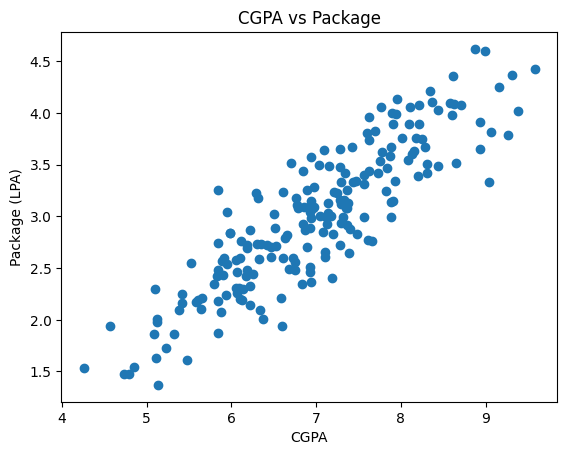

In [4]:
plt.scatter(df['cgpa'], df['package'])
plt.xlabel('CGPA')
plt.ylabel('Package (LPA)')
plt.title('CGPA vs Package')
plt.show()

## 3. Prepare features and target

In [5]:
X = df[['cgpa']]   # feature (2D)
y = df['package']  # target (1D)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((160, 1), (40, 1))

## 4. Train the model

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Coefficient (slope):', model.coef_[0])
print('Intercept:', model.intercept_)

Coefficient (slope): 0.5742564727019197
Intercept: -1.0270069374542108


## 5. Evaluate the model

In [7]:
y_pred = model.predict(X_test)

print('R2 Score:', r2_score(y_test, y_pred))
print('MSE:', mean_squared_error(y_test, y_pred))

R2 Score: 0.7730984312051673
MSE: 0.08417638361329656


## 6. Visualize the regression line

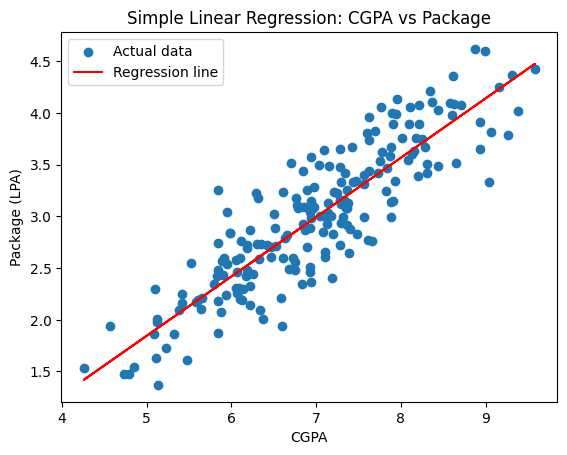

In [8]:
plt.scatter(df['cgpa'], df['package'], label='Actual data')
plt.plot(df['cgpa'], model.predict(df[['cgpa']]), color='red', label='Regression line')
plt.xlabel('CGPA')
plt.ylabel('Package (LPA)')
plt.title('Simple Linear Regression: CGPA vs Package')
plt.legend()
plt.show()

## 7. Predict package for a given CGPA
Enter a CGPA below and get the predicted package.

In [9]:
def predict_package(cgpa):
    cgpa_df = pd.DataFrame({'cgpa': [cgpa]})
    predicted = model.predict(cgpa_df)[0]
    return predicted

# Example usage:
cgpa_input = float(input('Enter your CGPA: '))
predicted_package = predict_package(cgpa_input)
print(f'Predicted Package for CGPA {cgpa_input}: {predicted_package:.2f} LPA')

Predicted Package for CGPA 6.89: 2.93 LPA
